# TRACE · Training and evaluation

In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "trace_core").exists():
    ROOT = ROOT.parent
if not (ROOT / "trace_core").exists():
    raise RuntimeError("Open this notebook from the TRACE project or its notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA = ROOT / "data" / "trace_synthetic_cases.csv"
ARTIFACTS = ROOT / "artifacts"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#f8fafc", "axes.edgecolor": "#d8e0ec", "axes.labelcolor": "#22344f", "text.color": "#22344f", "font.size": 10})
print(f"Project: {ROOT}")
print(f"Python: {sys.version.split()[0]}")

Project: C:\anujDrive\DL_Project_7th_sem
Python: 3.12.15


## 1. Training control

In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    command = [sys.executable, str(ROOT / "scripts" / "train_models.py"),
               "--export-synthetic", str(DATA),
               "--vae-epochs", "20", "--rbm-epochs", "25", "--batch-size", "256"]
    completed = subprocess.run(command, cwd=ROOT, text=True, capture_output=True, check=True)
    print(completed.stdout)
else:
    print("Using the existing saved training run. Set RUN_TRAINING=True to retrain.")

Using the existing saved training run. Set RUN_TRAINING=True to retrain.


## 2. Dataset and split integrity

In [3]:
from trace_core.config import ARTIFACT_FILES, INCIDENT_CLASSES, MARKOV_STATES
from trace_core.preprocessing import labeled_incident_groups, normalize_events, rbm_feature_matrix, sequence_feature_vector

raw = pd.read_csv(DATA)
events = normalize_events(raw)
manifest = json.loads((ARTIFACTS / "split_manifest.json").read_text(encoding="utf-8"))
groups = labeled_incident_groups(events)
by_id = {str(case.iloc[0]["incident_id"]): (label, case) for label, case in groups}
train_ids = set(manifest["train_incident_ids"])
calibration_ids = set(manifest["calibration_incident_ids"])
test_ids = set(manifest["test_incident_ids"])
assert not (train_ids & calibration_ids or train_ids & test_ids or calibration_ids & test_ids)
assert train_ids | calibration_ids | test_ids == set(by_id)
assert len(events) == len(raw)
print(f"Events: {len(events):,} · cases: {len(by_id):,}")
display(pd.DataFrame({"partition": ["Fit", "Calibration", "Untouched test"],
                      "cases": [len(train_ids), len(calibration_ids), len(test_ids)]}))
partition_counts = pd.crosstab(
    pd.Series(["Fit" if case_id in train_ids else "Calibration" if case_id in calibration_ids else "Test"
               for case_id in by_id], name="partition"),
    pd.Series([by_id[case_id][0] for case_id in by_id], name="category"),
)
display(partition_counts.reindex(columns=INCIDENT_CLASSES))
fit_vectors = {tuple(sequence_feature_vector(by_id[case_id][1]).round(6))
               for case_id in train_ids}
duplicate_test_vectors = sum(
    tuple(sequence_feature_vector(by_id[case_id][1]).round(6)) in fit_vectors
    for case_id in test_ids
)
display(pd.DataFrame([{"exact_test_feature_duplicates_in_fit": duplicate_test_vectors,
                       "test_cases": len(test_ids)}]))

Events: 34,831 · cases: 2,985


,partition,cases
0,Fit,1791
1,Calibration,597
2,Untouched test,597


category,Normal Activity,Account Compromise,Privilege Escalation,Suspicious Process Execution,Data Exfiltration,Denial-of-Service-like Activity,Multi-stage Attack
partition,,,,,,,
Calibration,300,82,63,52,43,33,24
Fit,900,246,189,156,129,99,72
Test,300,82,63,52,43,33,24


,exact_test_feature_duplicates_in_fit,test_cases
0,0,597


,Incident category,Cases
0,Normal Activity,1500
1,Account Compromise,410
2,Privilege Escalation,315
3,Suspicious Process Execution,260
4,Data Exfiltration,215
5,Denial-of-Service-like Activity,165
6,Multi-stage Attack,120


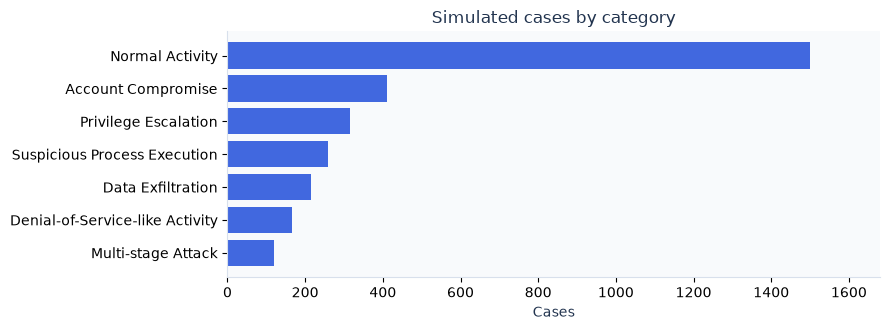

In [4]:
case_labels = events.drop_duplicates("incident_id")["incident_type"].value_counts().reindex(INCIDENT_CLASSES)
display(case_labels.rename_axis("Incident category").reset_index(name="Cases"))
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(case_labels.index[::-1], case_labels.values[::-1], color="#4168df")
ax.set(xlabel="Cases", title="Simulated cases by category", xlim=(0, max(case_labels) * 1.12))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Saved artifacts and training curves

In [5]:
from trace_core.pipeline import load_models

models = load_models(ARTIFACTS)
assert all(status == "Loaded" for status in models.statuses.values()), models.statuses
summary = json.loads((ARTIFACTS / ARTIFACT_FILES["summary"]).read_text(encoding="utf-8"))
saved_files = [ARTIFACT_FILES[key] for key in ("vae", "vae_encoder", "vae_decoder", "rbm", "rbm_metadata", "classifier", "markov", "summary")]
saved_files += ["split_manifest.json"]
artifact_rows = []
for name in saved_files:
    path = ARTIFACTS / name
    assert path.is_file() and path.stat().st_size > 0, path
    artifact_rows.append({"Artifact": name, "Size (KB)": round(path.stat().st_size / 1024, 1),
                          "SHA-256": hashlib.sha256(path.read_bytes()).hexdigest()[:16] + "…"})
display(pd.DataFrame(artifact_rows))
display(pd.DataFrame([{"Model": "VAE", "Epochs": summary["vae"]["epochs"],
                       "Final training loss": summary["vae"]["final_loss"]},
                      {"Model": "RBM", "Epochs": summary["rbm"]["epochs"],
                       "Final training loss": summary["rbm"]["final_reconstruction_error"]}]))
print("Training completed:", summary["trained_at"])
print("VAE threshold:", round(summary["vae"]["threshold"], 6), "—", summary["vae"]["threshold_source"])

,Artifact,Size (KB),SHA-256
0,vae_metadata.json,3.6,af4dab76ef3056e4…
1,vae_encoder.keras,65.6,dd9f43aa3cc52b01…
2,vae_decoder.keras,60.8,f1776596fe72069c…
3,rbm.keras,19.4,30adc7ab39fe759f…
4,rbm_metadata.json,0.8,4c101b0ccac9b732…
5,incident_classifier.joblib,3.6,b23c3300f90f4561…
6,markov.json,1.9,9de85121341a087d…
7,training_summary.json,8.2,796859159896125a…
8,split_manifest.json,55.6,98749dfa0150cd0d…


,Model,Epochs,Final training loss
0,VAE,20,0.038796
1,RBM,25,0.114653


Training completed: 2026-10-25T14:38:40.745199+00:00
VAE threshold: 0.056119 — 95th percentile of held-out normal case maximum errors


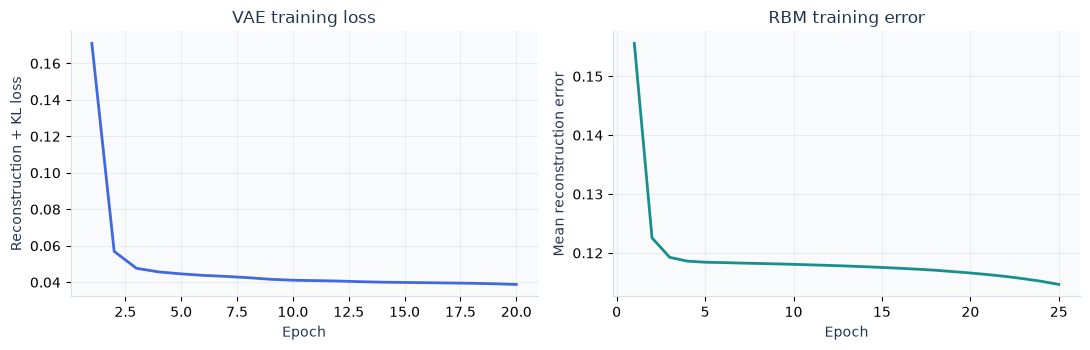

In [6]:
vae_loss = summary["vae"].get("epoch_loss", [])
rbm_loss = summary["rbm"].get("epoch_reconstruction_error", [])
if vae_loss and rbm_loss:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].plot(range(1, len(vae_loss) + 1), vae_loss, color="#4168df", linewidth=2)
    axes[0].set(xlabel="Epoch", ylabel="Reconstruction + KL loss", title="VAE training loss")
    axes[1].plot(range(1, len(rbm_loss) + 1), rbm_loss, color="#188f8d", linewidth=2)
    axes[1].set(xlabel="Epoch", ylabel="Mean reconstruction error", title="RBM training error")
    for ax in axes:
        ax.grid(alpha=.18)
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
else:
    print("This training summary predates per-epoch logging. Retrain to populate both curves.")

## 4. Held-out classifier and VAE results

,precision,recall,f1-score,support
Account Compromise,0.645,0.598,0.620,82.000
Data Exfiltration,0.784,0.930,0.851,43.000
Denial-of-Service-like Activity,1.000,0.970,0.985,33.000
Multi-stage Attack,0.792,0.792,0.792,24.000
Normal Activity,0.938,0.913,0.926,300.000
Privilege Escalation,0.612,0.651,0.631,63.000
Suspicious Process Execution,0.618,0.654,0.636,52.000
accuracy,0.819,0.819,0.819,0.819
macro avg,0.770,0.787,0.777,597.000
weighted avg,0.822,0.819,0.820,597.000


,Train macro F1,Test accuracy,Test balanced accuracy,Test macro F1,Test weighted F1,Test MCC,Test log loss,Test cases
0,0.783,0.8191,0.7867,0.7771,0.8198,0.7441,0.5594,597


,weight_exponent,calibration_macro_f1,calibration_balanced_accuracy,calibration_log_loss
0,0.0,0.7798,0.7558,0.5036
1,0.5,0.7831,0.7773,0.5207
2,1.0,0.7749,0.7857,0.5872


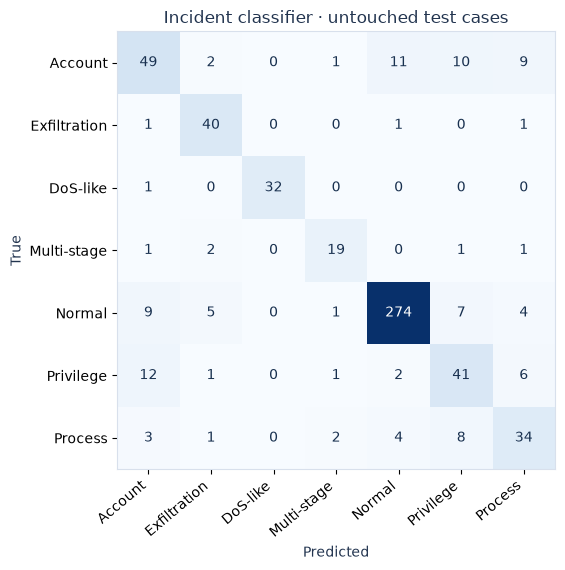

In [7]:
classifier = summary["classifier"]
class_report = pd.DataFrame(classifier["classification_report"]).T
display(class_report[["precision", "recall", "f1-score", "support"]].round(3))
display(pd.DataFrame([{"Train macro F1": classifier["training_macro_f1"],
                       "Test accuracy": classifier["accuracy"],
                       "Test balanced accuracy": classifier["balanced_accuracy"],
                       "Test macro F1": classifier["macro_f1"],
                       "Test weighted F1": classifier["weighted_f1"],
                       "Test MCC": classifier["matthews_corrcoef"],
                       "Test log loss": classifier["multiclass_log_loss"],
                       "Test cases": classifier["sequence_count"]}]).round(4))
display(pd.DataFrame(classifier["calibration_candidates"]).round(4))
labels = classifier["classes"]
short = {"Normal Activity": "Normal", "Account Compromise": "Account", "Privilege Escalation": "Privilege",
         "Suspicious Process Execution": "Process", "Data Exfiltration": "Exfiltration",
         "Denial-of-Service-like Activity": "DoS-like", "Multi-stage Attack": "Multi-stage"}
matrix = np.asarray(classifier["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7.5, 5.8))
ax.imshow(matrix, cmap="Blues")
ax.set_xticks(range(len(labels)), [short.get(label, label) for label in labels], rotation=40, ha="right")
ax.set_yticks(range(len(labels)), [short.get(label, label) for label in labels])
ax.set(xlabel="Predicted", ylabel="True", title="Incident classifier · untouched test cases")
for row in range(len(labels)):
    for col in range(len(labels)):
        ax.text(col, row, str(matrix[row, col]), ha="center", va="center", color="white" if matrix[row, col] > matrix.max() / 2 else "#18304f")
fig.tight_layout()
plt.show()

,Precision,Recall,F1,ROC AUC,Average precision,Incident prevalence,Threshold,Cases
0,0.9088,0.8384,0.8722,0.9378,0.9462,0.4975,0.0561,597


,Predicted normal,Predicted incident
True normal,275,25
True incident,48,249


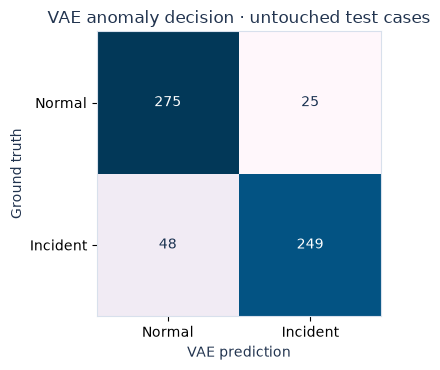

In [8]:
vae = summary["vae"]["metrics"]
from sklearn.metrics import average_precision_score
from trace_core.models.vae import reconstruction_errors
from trace_core.preprocessing import vae_feature_matrix
test_case_groups = [by_id[case_id] for case_id in manifest["test_incident_ids"]]
anomaly_truth = [int(label != "Normal Activity") for label, _ in test_case_groups]
anomaly_scores = [float(reconstruction_errors(models.vae, vae_feature_matrix(case)).max())
                  for _, case in test_case_groups]
average_precision = average_precision_score(anomaly_truth, anomaly_scores)
display(pd.DataFrame([{"Precision": vae["precision"], "Recall": vae["recall"],
                       "F1": vae["f1"], "ROC AUC": vae["roc_auc"],
                       "Average precision": average_precision,
                       "Incident prevalence": np.mean(anomaly_truth),
                       "Threshold": vae["threshold"], "Cases": vae["sequence_count"]}]).round(4))
anomaly_matrix = np.asarray(vae["confusion_matrix"])
display(pd.DataFrame(anomaly_matrix, index=["True normal", "True incident"],
                     columns=["Predicted normal", "Predicted incident"]))
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.imshow(anomaly_matrix, cmap="PuBu")
ax.set_xticks([0, 1], ["Normal", "Incident"])
ax.set_yticks([0, 1], ["Normal", "Incident"])
ax.set(xlabel="VAE prediction", ylabel="Ground truth", title="VAE anomaly decision · untouched test cases")
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(anomaly_matrix[row, col]), ha="center", va="center", color="white" if anomaly_matrix[row, col] > anomaly_matrix.max() / 2 else "#18304f")
fig.tight_layout()
plt.show()

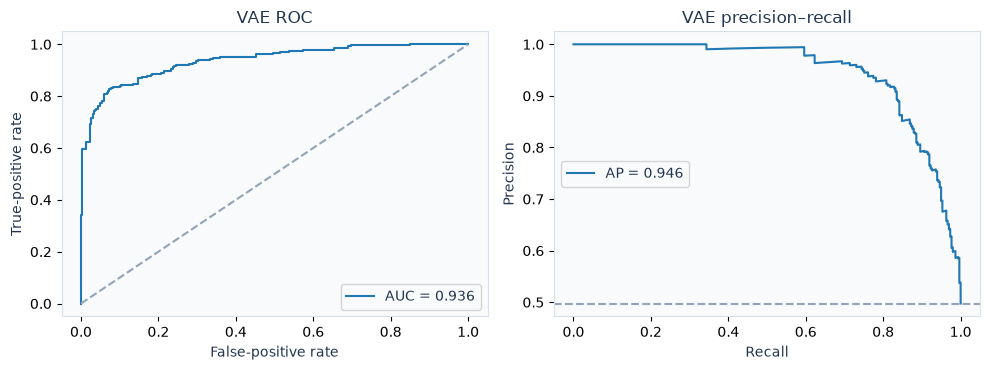

In [9]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc
fpr, tpr, _ = roc_curve(anomaly_truth, anomaly_scores)
precision, recall, _ = precision_recall_curve(anomaly_truth, anomaly_scores)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#94a3b8")
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="VAE ROC")
axes[0].legend()
axes[1].plot(recall, precision, label=f"AP = {average_precision:.3f}")
axes[1].axhline(np.mean(anomaly_truth), linestyle="--", color="#94a3b8")
axes[1].set(xlabel="Recall", ylabel="Precision", title="VAE precision–recall")
axes[1].legend()
fig.tight_layout()
plt.show()

## 5. RBM and Markov diagnostics

,RBM visible units,RBM hidden units,Contrastive divergence k,Held-out reconstruction error
0,26,12,1,0.1138


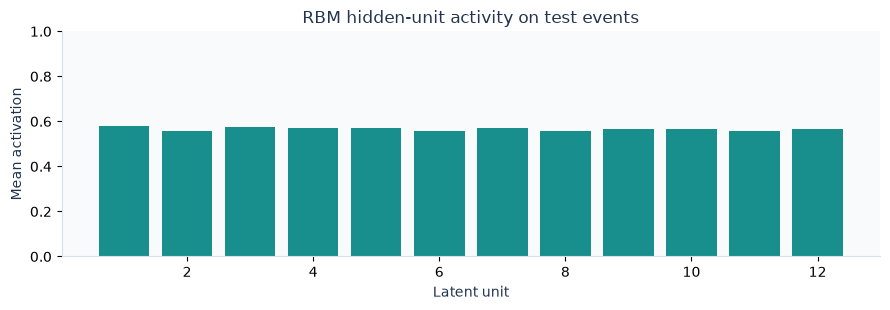

In [10]:
test_groups = [by_id[case_id] for case_id in manifest["test_incident_ids"]]
test_visible = np.concatenate([rbm_feature_matrix(case) for _, case in test_groups])
held_out_rbm_error = float(models.rbm.reconstruction_errors(test_visible).mean())
hidden_activation = models.rbm.transform(test_visible).mean(axis=0)
display(pd.DataFrame([{"RBM visible units": summary["rbm"]["visible_units"],
                       "RBM hidden units": summary["rbm"]["hidden_units"],
                       "Contrastive divergence k": summary["rbm"]["contrastive_divergence_k"],
                       "Held-out reconstruction error": held_out_rbm_error}]).round(4))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(np.arange(1, len(hidden_activation) + 1), hidden_activation, color="#188f8d")
ax.set(xlabel="Latent unit", ylabel="Mean activation", title="RBM hidden-unit activity on test events", ylim=(0, 1))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

,Held-out stage transitions,Next-stage top-one accuracy,Mean negative log likelihood
0,4900,0.3584,1.5214


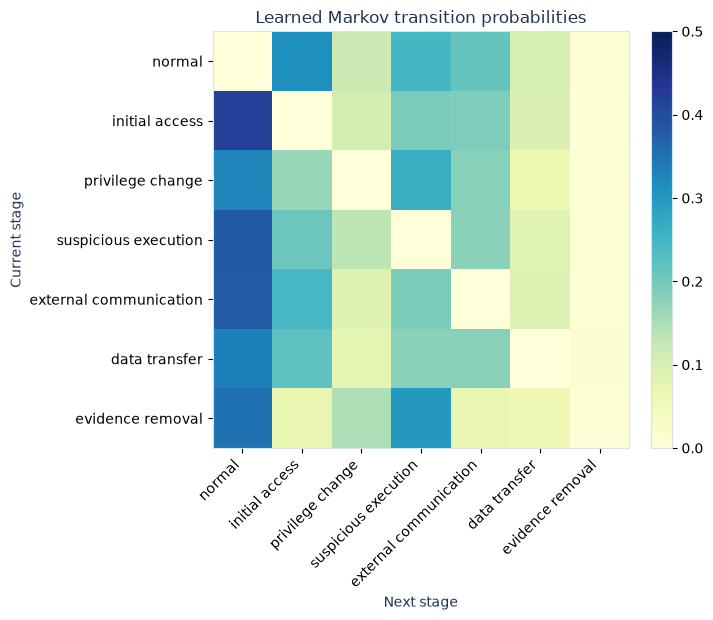

In [11]:
markov = summary["markov"]["metrics"]
display(pd.DataFrame([{"Held-out stage transitions": markov["held_out_transitions"],
                       "Next-stage top-one accuracy": markov["next_stage_top1_accuracy"],
                       "Mean negative log likelihood": markov["mean_negative_log_likelihood"]}]).round(4))
transition = models.markov.transition
fig, ax = plt.subplots(figsize=(8.5, 6.3))
image = ax.imshow(transition, cmap="YlGnBu", vmin=0, vmax=max(.5, float(transition.max())))
names = [name.replace("_", " ") for name in MARKOV_STATES]
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.set(xlabel="Next stage", ylabel="Current stage", title="Learned Markov transition probabilities")
fig.colorbar(image, ax=ax, fraction=.035, pad=.03)
fig.tight_layout()
plt.show()

## 6. Full saved-artifact pipeline audit

In [12]:
from scripts.evaluate_models import evaluate

audit = evaluate(DATA, ARTIFACTS)
display(pd.DataFrame([{"Test cases": audit["case_count"], "Category accuracy": audit["category_accuracy"],
                       "Category balanced accuracy": audit["category_balanced_accuracy"],
                       "Category macro F1": audit["category_macro_f1"],
                       "Category weighted F1": audit["category_weighted_f1"],
                       "Incident precision": audit["incident_precision"],
                       "Incident recall": audit["incident_recall"],
                       "Incident F1": audit["incident_f1"],
                       "Incident false-positive rate": audit["incident_false_positive_rate"],
                       "Separate demo accuracy": audit["separate_demo_accuracy"]}]).round(4))
display(pd.DataFrame(audit["category_report"]).T[["precision", "recall", "f1-score", "support"]].round(3))
display(pd.DataFrame(audit["separate_demo_scenarios"]))
print("Case-level errors:", len(audit["errors"]))
print("Audit saved:", ARTIFACTS / "evaluation_audit.json")

,Test cases,Category accuracy,Category balanced accuracy,Category macro F1,Category weighted F1,Incident precision,Incident recall,Incident F1,Incident false-positive rate,Separate demo accuracy
0,597,0.809,0.7861,0.7751,0.8121,0.8949,0.9461,0.9198,0.11,1.0


,precision,recall,f1-score,support
Normal Activity,0.943,0.890,0.916,300.000
Account Compromise,0.576,0.598,0.587,82.000
Privilege Escalation,0.612,0.651,0.631,63.000
Suspicious Process Execution,0.625,0.673,0.648,52.000
Data Exfiltration,0.784,0.930,0.851,43.000
Denial-of-Service-like Activity,1.000,0.970,0.985,33.000
Multi-stage Attack,0.826,0.792,0.809,24.000
accuracy,0.809,0.809,0.809,0.809
macro avg,0.767,0.786,0.775,597.000
weighted avg,0.817,0.809,0.812,597.000


,true_label,predicted_label,incident_detected
0,Normal Activity,Normal Activity,False
1,Account Compromise,Account Compromise,True
2,Privilege Escalation,Privilege Escalation,True
3,Suspicious Process Execution,Suspicious Process Execution,True
4,Data Exfiltration,Data Exfiltration,True
5,Denial-of-Service-like Activity,Denial-of-Service-like Activity,True
6,Multi-stage Attack,Multi-stage Attack,True


Case-level errors: 114
Audit saved: C:\anujDrive\DL_Project_7th_sem\artifacts\evaluation_audit.json


## 7. Independent showcase cases

In [13]:
from scripts.generate_showcase_datasets import CASES
from trace_core.pipeline import analyze_events

showcase_rows = []
for item in CASES:
    sample = normalize_events(pd.read_csv(ROOT / "data" / "showcase" / item["file"]))
    result = analyze_events(sample, models)
    showcase_rows.append({"case": item["file"], "expected": item["label"],
                          "predicted": result["incident_type"],
                          "correct": result["incident_type"] == item["label"],
                          "model_score": result["selected_hypothesis_probability"]})
display(pd.DataFrame(showcase_rows).round(3))
print("Showcase accuracy:", round(pd.DataFrame(showcase_rows)["correct"].mean(), 3))

,case,expected,predicted,correct,model_score
0,01_routine_activity.csv,Normal Activity,Normal Activity,True,0.936
1,02_account_takeover.csv,Account Compromise,Account Compromise,True,0.883
2,03_higher_access.csv,Privilege Escalation,Privilege Escalation,True,0.744
3,04_unusual_program.csv,Suspicious Process Execution,Suspicious Process Execution,True,0.777
4,05_possible_data_loss.csv,Data Exfiltration,Data Exfiltration,True,0.974
5,06_service_disruption.csv,Denial-of-Service-like Activity,Denial-of-Service-like Activity,True,0.900
6,07_linked_incident.csv,Multi-stage Attack,Multi-stage Attack,True,0.994


Showcase accuracy: 1.0


## 8. Recorded lab telemetry

In [14]:
recorded_path = ARTIFACTS / "recorded_telemetry_check.json"
if recorded_path.exists():
    recorded = json.loads(recorded_path.read_text(encoding="utf-8"))
    current_hash = hashlib.sha256((ARTIFACTS / ARTIFACT_FILES["classifier"]).read_bytes()).hexdigest()
    if recorded.get("classifier_sha256") == current_hash:
        display(pd.DataFrame(recorded["cases"])[["capture", "raw_events", "mapped_events",
                                                 "mapping_coverage", "source_tactic",
                                                 "predicted_category", "incident_detected",
                                                 "model_score"]].round(3))
    else:
        print("Recorded telemetry results are for older artifacts; rerun the recorded check.")
else:
    print("Run python scripts/evaluate_recorded_telemetry.py to fill this table.")

,capture,raw_events,mapped_events,mapping_coverage,source_tactic,predicted_category,incident_detected,model_score
0,cmd_service_mod_fax.zip,437,17,0.039,Privilege Escalation,Suspicious Process Execution,True,0.520
1,empire_launcher_vbs.zip,2067,146,0.071,Suspicious Process Execution,Denial-of-Service-like Activity,True,0.502
